In [30]:
import pandas as pd
import numpy as np
from collections import Counter

In [31]:
data = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
data = data.dropna()

In [32]:
X = data.drop("target", axis=1).values.astype(float)
y = data["target"].values.astype(int)

if not np.all(np.isin(np.unique(y), [0, 1])):
    raise ValueError("This code requires a binary target containing 0 and 1.")

feature_names = data.drop("target", axis=1).columns.tolist()

In [33]:
def accuracy(actual, predicted):
    return np.mean(np.array(actual) == np.array(predicted)) * 100


def gini(y):
    if len(y) == 0:
        return 0

    p = np.mean(y)
    return 1 - p**2 - (1 - p)**2


def get_thresholds(values):
    unique_values = np.unique(values)

    if len(unique_values) <= 10:
        return (unique_values[:-1] + unique_values[1:]) / 2

    thresholds = np.percentile(
        values, [10, 20, 30, 40, 50, 60, 70, 80, 90]
    )

    return np.unique(thresholds)

In [34]:
def build_rf_tree(X, y, depth=0, max_depth=5,
                  min_samples=5, importance=None):

    if importance is None:
        importance = {}

    if (depth >= max_depth or len(y) < min_samples
            or len(np.unique(y)) == 1):
        return int(np.mean(y) >= 0.5)

    best_gain = 0
    best_feature = None
    best_threshold = None

    number_features = max(1, int(np.sqrt(X.shape[1])))
    features = np.random.choice(
        X.shape[1], number_features, replace=False
    )

    parent_gini = gini(y)

    for feature in features:
        for threshold in get_thresholds(X[:, feature]):

            left = X[:, feature] <= threshold
            right = ~left

            if left.sum() == 0 or right.sum() == 0:
                continue

            gain = parent_gini - (
                left.sum() / len(y) * gini(y[left])
                + right.sum() / len(y) * gini(y[right])
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return int(np.mean(y) >= 0.5)

    importance[best_feature] = (
        importance.get(best_feature, 0) + best_gain
    )

    left = X[:, best_feature] <= best_threshold
    right = ~left

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_rf_tree(
            X[left], y[left], depth + 1,
            max_depth, min_samples, importance
        ),
        "right": build_rf_tree(
            X[right], y[right], depth + 1,
            max_depth, min_samples, importance
        )
    }


def predict_rf_tree(tree, row):

    if not isinstance(tree, dict):
        return tree

    if row[tree["feature"]] <= tree["threshold"]:
        return predict_rf_tree(tree["left"], row)

    return predict_rf_tree(tree["right"], row)


def train_random_forest(X, y, number_trees=10):
    trees = []
    importance = {}

    for _ in range(number_trees):
        indices = np.random.choice(
            len(X), len(X), replace=True
        )

        tree = build_rf_tree(
            X[indices], y[indices],
            max_depth=5,
            min_samples=5,
            importance=importance
        )

        trees.append(tree)

    return trees, importance


def predict_random_forest(trees, X):
    predictions = []

    for row in X:
        votes = [
            predict_rf_tree(tree, row)
            for tree in trees
        ]

        predictions.append(Counter(votes).most_common(1)[0][0])

    return np.array(predictions)

In [35]:
def sigmoid(x):
    x = np.clip(x, -30, 30)
    return 1 / (1 + np.exp(-x))


def build_boost_tree(X, grad, hess, depth=0,
                     max_depth=2, reg=1.0,
                     importance=None):

    if importance is None:
        importance = {}

    if depth >= max_depth or len(X) < 5:
        return -np.sum(grad) / (np.sum(hess) + reg)

    best_gain = 0
    best_feature = None
    best_threshold = None

    total_grad = np.sum(grad)
    total_hess = np.sum(hess)

    for feature in range(X.shape[1]):
        for threshold in get_thresholds(X[:, feature]):

            left = X[:, feature] <= threshold
            right = ~left

            if left.sum() == 0 or right.sum() == 0:
                continue

            G_left = np.sum(grad[left])
            H_left = np.sum(hess[left])

            G_right = np.sum(grad[right])
            H_right = np.sum(hess[right])

            gain = 0.5 * (
                G_left**2 / (H_left + reg)
                + G_right**2 / (H_right + reg)
                - total_grad**2 / (total_hess + reg)
            )

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    if best_feature is None:
        return -total_grad / (total_hess + reg)

    importance[best_feature] = (
        importance.get(best_feature, 0) + best_gain
    )

    left = X[:, best_feature] <= best_threshold
    right = ~left

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "left": build_boost_tree(
            X[left], grad[left], hess[left],
            depth + 1, max_depth, reg, importance
        ),
        "right": build_boost_tree(
            X[right], grad[right], hess[right],
            depth + 1, max_depth, reg, importance
        )
    }


def predict_boost_tree(tree, row):

    if not isinstance(tree, dict):
        return tree

    if row[tree["feature"]] <= tree["threshold"]:
        return predict_boost_tree(tree["left"], row)

    return predict_boost_tree(tree["right"], row)


def train_boosting(X, y, number_trees=30, learning_rate=0.1):
    probability = np.clip(np.mean(y), 0.001, 0.999)
    base_score = np.log(probability / (1 - probability))

    scores = np.full(len(y), base_score, dtype=float)
    trees = []
    importance = {}

    for _ in range(number_trees):
        probabilities = sigmoid(scores)

        gradients = probabilities - y
        hessians = probabilities * (1 - probabilities)

        tree = build_boost_tree(
            X, gradients, hessians,
            max_depth=2,
            reg=1.0,
            importance=importance
        )

        predictions = np.array([
            predict_boost_tree(tree, row) for row in X
        ])

        scores += learning_rate * predictions
        trees.append(tree)

    return base_score, trees, learning_rate, importance


def predict_boosting(model, X):
    base_score, trees, learning_rate, importance = model

    scores = np.full(len(X), base_score, dtype=float)

    for tree in trees:
        predictions = np.array([
            predict_boost_tree(tree, row) for row in X
        ])

        scores += learning_rate * predictions

    return (sigmoid(scores) >= 0.5).astype(int)

In [36]:
np.random.seed(42)

k = 5
indices = np.random.permutation(len(X))
folds = np.array_split(indices, k)

rf_scores = []
boost_scores = []

rf_importance_total = np.zeros(X.shape[1])
boost_importance_total = np.zeros(X.shape[1])

for fold_number in range(k):

    print("Running fold", fold_number + 1, "of", k)

    test_indices = folds[fold_number]

    train_indices = np.concatenate([
        folds[i] for i in range(k) if i != fold_number
    ])

    X_train = X[train_indices]
    y_train = y[train_indices]

    X_test = X[test_indices]
    y_test = y[test_indices]

    rf_trees, rf_importance = train_random_forest(
        X_train, y_train, number_trees=10
    )

    rf_predictions = predict_random_forest(rf_trees, X_test)
    rf_acc = accuracy(y_test, rf_predictions)
    rf_scores.append(rf_acc)

    for feature, value in rf_importance.items():
        rf_importance_total[feature] += value

    
    boost_model = train_boosting(
        X_train, y_train,
        number_trees=30,
        learning_rate=0.1
    )

    boost_predictions = predict_boosting(boost_model, X_test)
    boost_acc = accuracy(y_test, boost_predictions)
    boost_scores.append(boost_acc)

    for feature, value in boost_model[3].items():
        boost_importance_total[feature] += value

    print("Random Forest accuracy:", round(rf_acc, 2), "%")
    print("Gradient Boosting accuracy:", round(boost_acc, 2), "%")
    print("-" * 40)

Running fold 1 of 5
Random Forest accuracy: 84.39 %
Gradient Boosting accuracy: 78.54 %
----------------------------------------
Running fold 2 of 5
Random Forest accuracy: 90.24 %
Gradient Boosting accuracy: 89.27 %
----------------------------------------
Running fold 3 of 5
Random Forest accuracy: 91.22 %
Gradient Boosting accuracy: 87.8 %
----------------------------------------
Running fold 4 of 5
Random Forest accuracy: 91.71 %
Gradient Boosting accuracy: 88.29 %
----------------------------------------
Running fold 5 of 5
Random Forest accuracy: 87.8 %
Gradient Boosting accuracy: 84.39 %
----------------------------------------


In [37]:
print("\nFINAL 5-FOLD RESULTS")
print("=" * 40)

print("Random Forest fold accuracies:", np.round(rf_scores, 2))
print("Random Forest mean accuracy:", round(np.mean(rf_scores), 2), "%")
print("Random Forest standard deviation:", round(np.std(rf_scores), 2), "%")

print("\nGradient Boosting fold accuracies:", np.round(boost_scores, 2))
print("Gradient Boosting mean accuracy:", round(np.mean(boost_scores), 2), "%")
print("Gradient Boosting standard deviation:", round(np.std(boost_scores), 2), "%")

if np.mean(rf_scores) > np.mean(boost_scores):
    print("\nRandom Forest performed better on average.")
elif np.mean(boost_scores) > np.mean(rf_scores):
    print("\nGradient Boosting performed better on average.")
else:
    print("\nBoth models achieved the same mean accuracy.")


FINAL 5-FOLD RESULTS
Random Forest fold accuracies: [84.39 90.24 91.22 91.71 87.8 ]
Random Forest mean accuracy: 89.07 %
Random Forest standard deviation: 2.7 %

Gradient Boosting fold accuracies: [78.54 89.27 87.8  88.29 84.39]
Gradient Boosting mean accuracy: 85.66 %
Gradient Boosting standard deviation: 3.92 %

Random Forest performed better on average.



FEATURE IMPORTANCE COMPARISON
 Feature  Random Forest Importance  Gradient Boosting Importance
 thalach                 15.943663                    176.361177
      cp                 13.965414                   2299.594704
     age                 12.452534                    287.911410
 oldpeak                 11.945164                    686.930862
    thal                 10.678345                   1451.895404
    chol                 10.566067                     45.607668
trestbps                 10.544944                      1.204974
      ca                  9.226185                   1512.843000
   slope                  6.130164                    442.477026
     sex                  5.337152                    307.964824
 restecg                  4.780482                     82.197403
   exang                  4.566263                    439.078953
     fbs                  2.377370                      0.000000


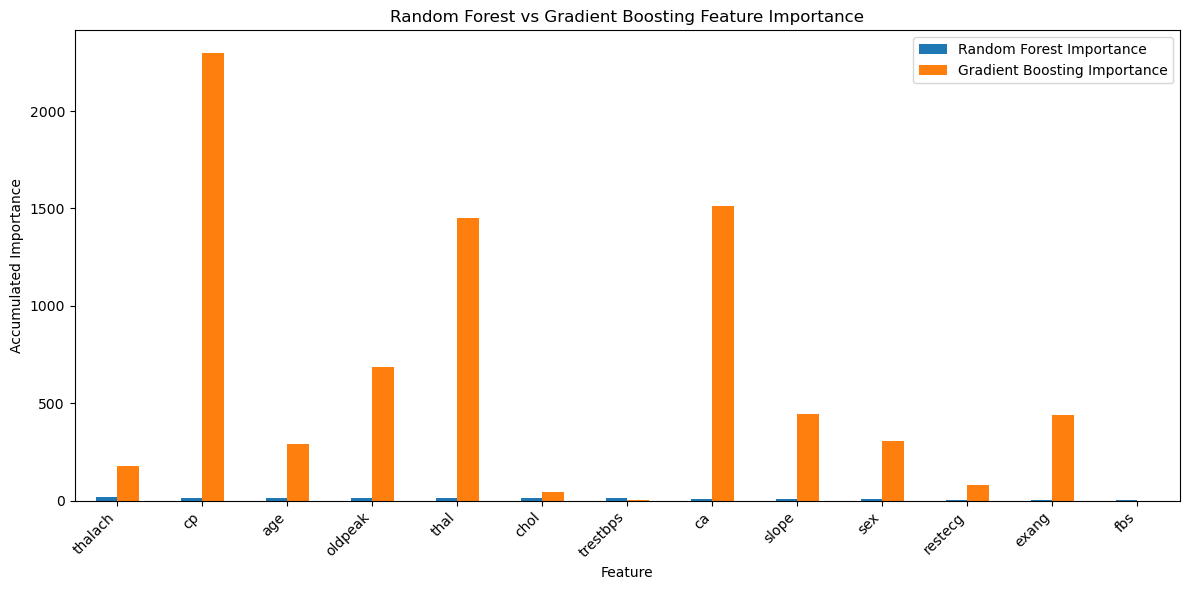

In [38]:
importance_table = pd.DataFrame({
    "Feature": feature_names,
    "Random Forest Importance": rf_importance_total,
    "Gradient Boosting Importance": boost_importance_total
})

importance_table = importance_table.sort_values(
    "Random Forest Importance", ascending=False
)

print("\nFEATURE IMPORTANCE COMPARISON")
print(importance_table.to_string(index=False))

importance_table.set_index("Feature").plot(
    kind="bar",
    figsize=(12, 6),
    title="Random Forest vs Gradient Boosting Feature Importance"
)

import matplotlib.pyplot as plt
plt.ylabel("Accumulated Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
